Proper evaluation and threshold tuning

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

# clone() makes a fresh, untrained copy of a model with the same settings
from sklearn.base import clone
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, RocCurveDisplay,
    roc_auc_score, average_precision_score,
    precision_recall_curve,
    precision_score, recall_score, f1_score,
    classification_report,
)

load the data and the saved models

In [28]:
# Data from Stage 3
X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train = pd.read_csv("../data/processed/y_train.csv")["Class"]
y_test = pd.read_csv("../data/processed/y_test.csv")["Class"]

# Models from Stage 5 (no retraining needed; we load them from disk)
log_reg = joblib.load("../models/log_reg.pkl")
rf = joblib.load("../models/random_forest.pkl")
xgb = joblib.load("../models/xgboost.pkl")

# Keep them in a dictionary so we can loop over them
models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf,
    "XGBoost": xgb,
}
print("Loaded:", list(models.keys()))

Loaded: ['Logistic Regression', 'Random Forest', 'XGBoost']


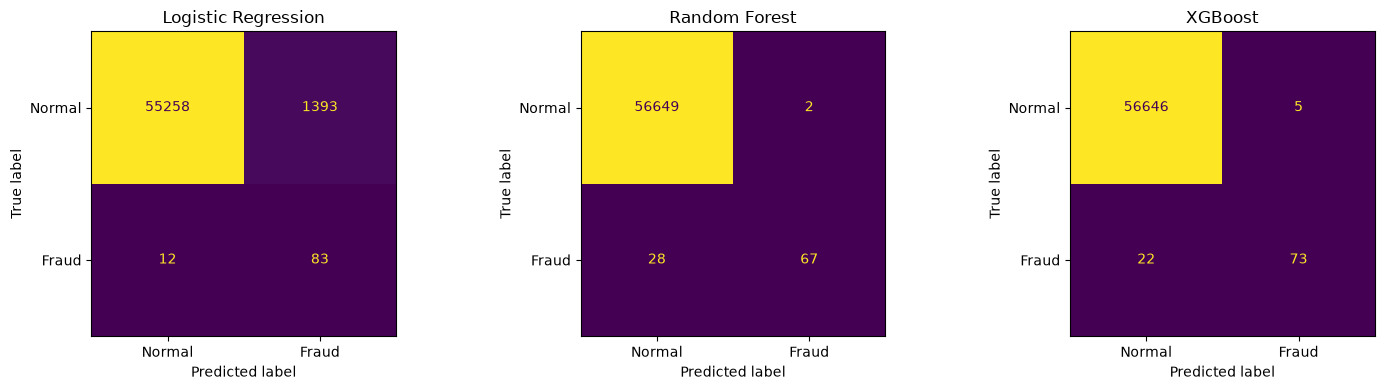

In [29]:
# Draw one confusion matrix per model, side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        ax=ax,
        colorbar=False,
        values_format="d",                          # show whole numbers, not 1e+03
        display_labels=["Normal", "Fraud"],
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

Precision-Recall curves

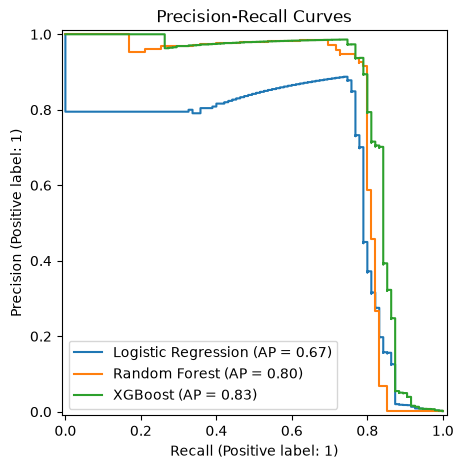

In [30]:
fig, ax = plt.subplots(figsize=(7, 5))

# Draw one curve per model on the same chart
for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)

ax.set_title("Precision-Recall Curves")
plt.show()

ROC curves

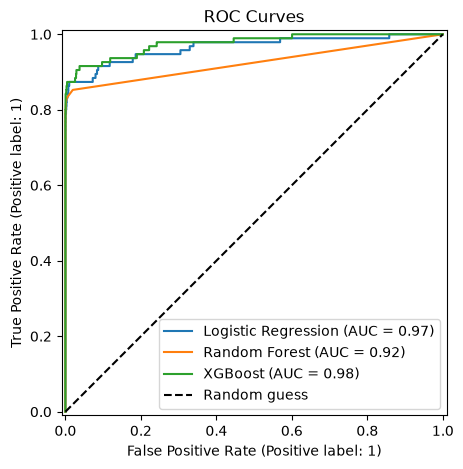

In [31]:
fig, ax = plt.subplots(figsize=(7, 5))

for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)

# Diagonal dashed line = a model that guesses randomly
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC Curves")
ax.legend()
plt.show()

compare ROC-AUC and PR-AUC numerically

In [32]:
rows = []
for name, model in models.items():
    # Probability of fraud for each test transaction
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "ROC-AUC": round(roc_auc_score(y_test, prob), 4),
        "PR-AUC": round(average_precision_score(y_test, prob), 4),
    })

pd.DataFrame(rows)

,Model,ROC-AUC,PR-AUC
0,Logistic Regression,0.9657,0.6719
1,Random Forest,0.9246,0.7963
2,XGBoost,0.9762,0.8300


In [33]:
# Precision, recall and F1 for each class in one table (XGBoost, default threshold 0.5)
xgb_pred = xgb.predict(X_test)
print(classification_report(y_test, xgb_pred, target_names=["Normal", "Fraud"], digits=3))

              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     56651
       Fraud      0.936     0.768     0.844        95

    accuracy                          1.000     56746
   macro avg      0.968     0.884     0.922     56746
weighted avg      1.000     1.000     1.000     56746



Threshold tuning

A model outputs a probability of fraud. By default, “fraud” means probability ≥ 0.5, but 0.5 is just a convention, not a law. Lowering the threshold catches more fraud (higher recall, lower precision). Raising it flags fewer, surer cases (higher precision, lower recall).

Important rule: never choose the threshold by looking at the test set. That’s leakage again, and the test scores would be too optimistic. Instead, we hold out a validation set from the training data, choose the threshold there, and then use the test set once for the final score.

Build a validation set and find the best threshold

In [34]:
# The model we are tuning (change to rf if Random Forest looked clearly better for you)
best_model = xgb

# Split the TRAINING data again: 80% to train, 20% as validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    stratify=y_train,       # keep the same fraud ratio in both parts
    random_state=42,
)

# Make a fresh copy of the model with identical settings and train it on the smaller set
tuning_model = clone(best_model)
tuning_model.fit(X_tr, y_tr)

# Fraud probabilities on the validation set
val_prob = tuning_model.predict_proba(X_val)[:, 1]

compute precision and recall at every possible threshold

In [35]:
# For each threshold, this gives the precision and recall we would get
precision, recall, thresholds = precision_recall_curve(y_val, val_prob)

# precision and recall have one extra value at the end, so we drop it to match thresholds
precision, recall = precision[:-1], recall[:-1]

# F1 at every threshold (the tiny 1e-12 avoids dividing by zero)
f1 = 2 * precision * recall / (precision + recall + 1e-12)

# The threshold with the highest F1 score
best_idx = np.argmax(f1)
best_threshold = thresholds[best_idx]

print("Best threshold:", round(best_threshold, 4))
print("Validation precision:", round(precision[best_idx], 3))
print("Validation recall:   ", round(recall[best_idx], 3))
print("Validation F1:       ", round(f1[best_idx], 3))


Best threshold: 0.9212
Validation precision: 0.985
Validation recall:    0.855
Validation F1:        0.915


Because we gave fraud a huge weight with scale_pos_weight, the model’s probabilities are pushed upward. Don’t be surprised if the best threshold is well above 0.5.

visualize the trade-off

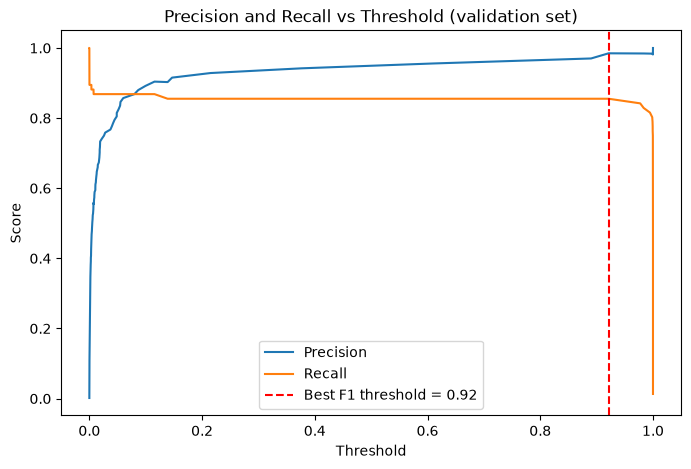

In [36]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision, label="Precision")
plt.plot(thresholds, recall, label="Recall")

# Vertical line at the chosen threshold
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Best F1 threshold = {best_threshold:.2f}")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Threshold (validation set)")
plt.legend()
plt.show()

You’ll see precision rising and recall falling as the threshold increases. That is the trade-off, drawn as a chart.

Apply it to the test set (the final check)

In [37]:
# Probabilities from the FULL model (trained on all training data) for the test set
test_prob = best_model.predict_proba(X_test)[:, 1]

def scores(threshold):
    """Return the metrics on the test set for a given threshold."""
    # Predict fraud (1) whenever probability >= threshold, otherwise normal (0)
    pred = (test_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "Threshold": round(threshold, 3),
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "F1": round(f1_score(y_test, pred), 3),
        "Frauds caught": tp,
        "Frauds missed": fn,
        "False alarms": fp,
    }

# Compare the default threshold with our tuned one
pd.DataFrame([scores(0.5), scores(best_threshold)], index=["Default (0.5)", "Tuned"])

,Threshold,Precision,Recall,F1,Frauds caught,Frauds missed,False alarms
Default (0.5),0.500,0.936,0.768,0.844,73,22,5
Tuned,0.921,0.986,0.747,0.850,71,24,1


The tuned threshold should improve the balance, usually by cutting false alarms a lot while losing only a few frauds.

A business-style threshold (optional but impressive)

Real banks often say: “We must catch at least 85% of fraud. Within that, make false alarms as few as possible.”

In [38]:
# Target: catch at least 85% of fraud on the validation set
target_recall = 0.85

# Find all thresholds that reach that recall
valid = recall >= target_recall

# Among those, take the highest threshold (fewest false alarms)
business_threshold = thresholds[valid].max()

print("Threshold for recall >= 85%:", round(business_threshold, 4))
pd.DataFrame([scores(business_threshold)], index=["Business rule"])

# If recall on the test set lands a little under 85%, that’s normal. 
# Validation and test sets differ slightly, and there are only about 95 test frauds.

Threshold for recall >= 85%: 0.9212


,Threshold,Precision,Recall,F1,Frauds caught,Frauds missed,False alarms
Business rule,0.921,0.986,0.747,0.85,71,24,1


Save the chosen threshold

In [39]:
# Save the threshold so the final pipeline in Stage 7 can reuse it
joblib.dump(best_threshold, "../models/threshold.pkl")
print("Saved threshold:", round(best_threshold, 4))

Saved threshold: 0.9212
